<a href="https://colab.research.google.com/github/Venkat-267-byte/Deep-Learning-/blob/main/Skill/Skill%206.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Install required libraries

!pip install pycocotools opencv-python-headless pandas matplotlib seaborn pillow


In [2]:

import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter
from pycocotools.coco import COCO

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Install Hugging Face library

!pip install -q huggingface_hub

from huggingface_hub import snapshot_download

print("Hugging Face library ready!")


Hugging Face library ready!


In [4]:

from huggingface_hub import hf_hub_download
import json

annotation_path = hf_hub_download(
    repo_id="iisc-aim/BMD-45",
    filename="BMD-45-Train/_annotations.coco.json",
    repo_type="dataset"
)

with open(annotation_path, "r") as f:
    coco_data = json.load(f)

print("Annotations loaded successfully!")
print("Images:", len(coco_data["images"]))
print("Annotations:", len(coco_data["annotations"]))
print("Classes:", len(coco_data["categories"]))



BMD-45-Train/_annotations.coco.json: reconstructing file:   0%|          |  0.00B / 49.4MB            

BMD-45-Train/_annotations.coco.json: downloading bytes:           |  0.00B            

Annotations loaded successfully!
Images: 35792
Annotations: 373132
Classes: 13


In [5]:

import random
from collections import defaultdict

random.seed(42)

images_by_class = defaultdict(set)
image_lookup = {img["id"]: img for img in coco_data["images"]}

for ann in coco_data["annotations"]:
    images_by_class[ann["category_id"]].add(ann["image_id"])

selected_ids = set()

# Select up to 20 images per class
for category_id, image_ids in images_by_class.items():
    selected_ids.update(
        random.sample(list(image_ids), min(20, len(image_ids)))
    )

# Fill remaining slots up to 300
remaining = list(set(image_lookup) - selected_ids)
if len(selected_ids) < 300:
    selected_ids.update(
        random.sample(remaining, min(300 - len(selected_ids), len(remaining)))
    )

selected_images = [image_lookup[i] for i in selected_ids]

print("Selected images:", len(selected_images))


Selected images: 300


In [6]:

from concurrent.futures import ThreadPoolExecutor
from tqdm.notebook import tqdm

def download_image(img):
    return hf_hub_download(
        repo_id="iisc-aim/BMD-45",
        filename="BMD-45-Train/" + img["file_name"],
        repo_type="dataset",
        local_dir="/content/bmd45_sample"
    )

with ThreadPoolExecutor(max_workers=8) as executor:
    downloaded_paths = list(tqdm(
        executor.map(download_image, selected_images),
        total=len(selected_images)
    ))

print("Image download completed!")


  0%|          | 0/300 [00:00<?, ?it/s]

BMD-45-Train/images_006/872843.png: reconstructing file:   0%|          |  0.00B / 3.10MB            

BMD-45-Train/images_001/229233.png: reconstructing file:   0%|          |  0.00B / 3.60MB            

BMD-45-Train/images_001/137192.png: reconstructing file:   0%|          |  0.00B / 2.65MB            

BMD-45-Train/images_001/167798.png: reconstructing file:   0%|          |  0.00B / 2.77MB            

BMD-45-Train/images_004/664963.png: reconstructing file:   0%|          |  0.00B / 3.35MB            

... (375 outputs left out)

BMD-45-Train/images_004/580128.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_000/5734.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_003/469432.png: downloading bytes:           |  0.00B            

BMD-45-Train/images_000/25628.png: downloading bytes:           |  0.00B            

In [7]:

import random
from collections import defaultdict

random.seed(42)

# Group image IDs by object category
images_by_class = defaultdict(set)

image_lookup = {
    img["id"]: img for img in coco_data["images"]
}

for ann in coco_data["annotations"]:
    images_by_class[ann["category_id"]].add(
        ann["image_id"]
    )

# Select up to 20 images from each category
selected_ids = set()

for category_id, image_ids in images_by_class.items():
    image_ids = list(image_ids)

    selected_ids.update(
        random.sample(
            image_ids,
            min(20, len(image_ids))
        )
    )

# Fill the remaining slots up to 300
remaining = list(set(image_lookup) - selected_ids)

if len(selected_ids) < 300:
    selected_ids.update(
        random.sample(
            remaining,
            min(300 - len(selected_ids), len(remaining))
        )
    )

selected_images = [
    image_lookup[i] for i in selected_ids
]

print("Total selected images:", len(selected_images))
print("Available categories:", len(images_by_class))


Total selected images: 300
Available categories: 13


In [8]:

import glob

image_files = glob.glob(
    "/content/bmd45_sample/BMD-45-Train/**/*.png",
    recursive=True
)

print("Total downloaded images:", len(image_files))
print("Sample image paths:")

for path in image_files[:10]:
    print(path)


Total downloaded images: 300
Sample image paths:
/content/bmd45_sample/BMD-45-Train/images_003/544943.png
/content/bmd45_sample/BMD-45-Train/images_003/459065.png
/content/bmd45_sample/BMD-45-Train/images_003/461218.png
/content/bmd45_sample/BMD-45-Train/images_003/463312.png
/content/bmd45_sample/BMD-45-Train/images_003/450745.png
/content/bmd45_sample/BMD-45-Train/images_003/488387.png
/content/bmd45_sample/BMD-45-Train/images_003/507904.png
/content/bmd45_sample/BMD-45-Train/images_003/491488.png
/content/bmd45_sample/BMD-45-Train/images_003/445315.png
/content/bmd45_sample/BMD-45-Train/images_003/547673.png


In [9]:

import cv2
import numpy as np
import pandas as pd
import os

image_quality = []

for path in image_files:
    img = cv2.imread(path)

    if img is None:
        continue

    height, width = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Measure sharpness
    sharpness = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    # Measure brightness
    brightness = np.mean(gray)

    image_quality.append({
        "Image": os.path.basename(path),
        "Width": width,
        "Height": height,
        "Resolution": width * height,
        "Brightness": round(brightness, 2),
        "Sharpness": round(sharpness, 2)
    })

quality_df = pd.DataFrame(image_quality)

print("Image quality analysis completed!")
print("Total images analysed:", len(quality_df))

quality_df.head(10)


Image quality analysis completed!
Total images analysed: 300


,Image,Width,Height,Resolution,Brightness,Sharpness
0,544943.png,1920,1080,2073600,141.56,1646.76
1,459065.png,1920,1080,2073600,137.41,874.85
2,461218.png,1920,1080,2073600,137.35,87.25
3,463312.png,1920,1080,2073600,143.29,93.15
4,450745.png,1920,1080,2073600,143.55,229.45
5,488387.png,1920,1080,2073600,118.69,1056.83
6,507904.png,1920,1080,2073600,122.57,152.06
7,491488.png,1920,1080,2073600,137.94,814.84
8,445315.png,1920,1080,2073600,139.13,493.33
9,547673.png,1920,1080,2073600,138.85,339.87


In [10]:

quality_df[["Width", "Height", "Brightness", "Sharpness"]].describe()


,Width,Height,Brightness,Sharpness
count,300.0,300.0,300.000000,300.000000
mean,1920.0,1080.0,136.594100,633.557867
std,0.0,0.0,10.671325,450.869724
min,1920.0,1080.0,77.450000,52.740000
25%,1920.0,1080.0,132.970000,300.482500
50%,1920.0,1080.0,137.940000,525.725000
75%,1920.0,1080.0,142.820000,850.662500
max,1920.0,1080.0,182.070000,2473.210000


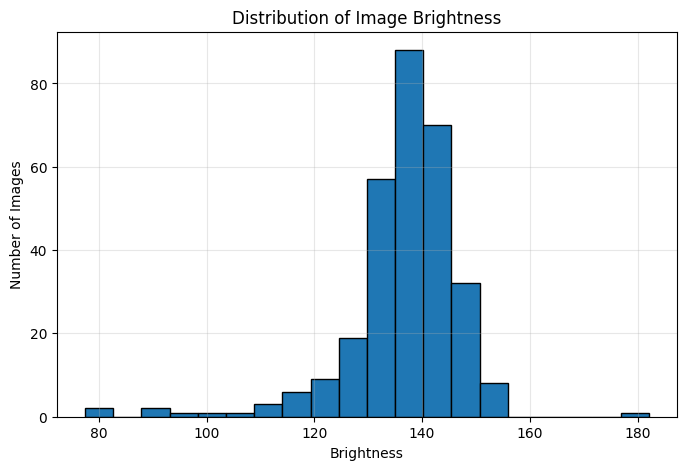

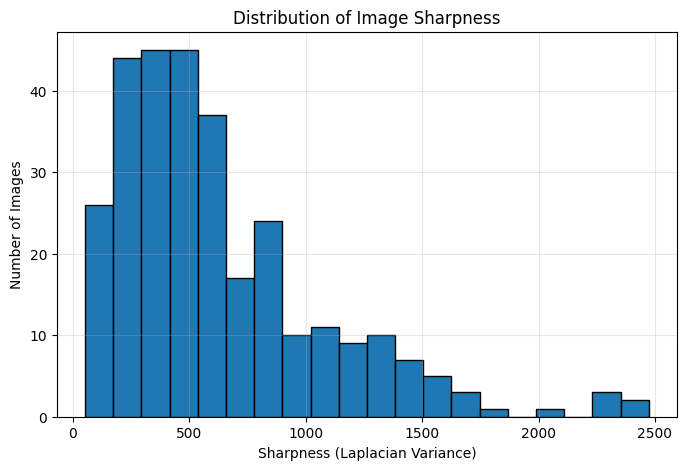

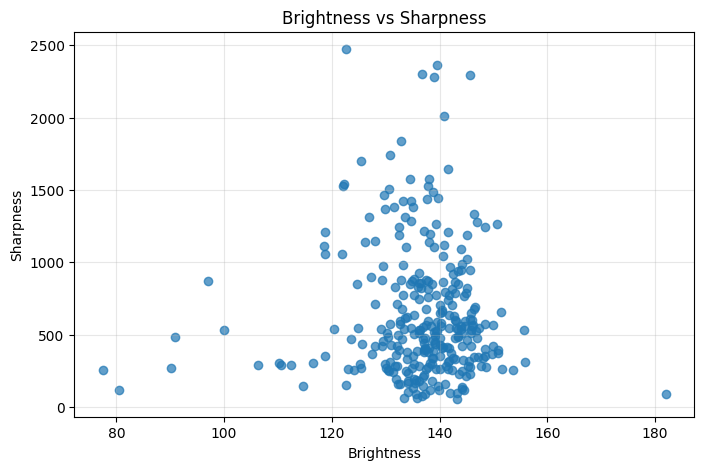

In [11]:

# 1. Brightness Distribution

plt.figure(figsize=(8, 5))
plt.hist(quality_df["Brightness"], bins=20, edgecolor="black")
plt.title("Distribution of Image Brightness")
plt.xlabel("Brightness")
plt.ylabel("Number of Images")
plt.grid(alpha=0.3)
plt.show()


# 2. Sharpness Distribution

plt.figure(figsize=(8, 5))
plt.hist(quality_df["Sharpness"], bins=20, edgecolor="black")
plt.title("Distribution of Image Sharpness")
plt.xlabel("Sharpness (Laplacian Variance)")
plt.ylabel("Number of Images")
plt.grid(alpha=0.3)
plt.show()


# 3. Brightness vs Sharpness

plt.figure(figsize=(8, 5))
plt.scatter(
    quality_df["Brightness"],
    quality_df["Sharpness"],
    alpha=0.7
)
plt.title("Brightness vs Sharpness")
plt.xlabel("Brightness")
plt.ylabel("Sharpness")
plt.grid(alpha=0.3)
plt.show()


In [12]:

def classify_quality(row):
    if row["Sharpness"] < 100:
        return "Blurry"
    elif row["Brightness"] < 100:
        return "Low Light"
    elif row["Sharpness"] > 500:
        return "Clear"
    else:
        return "Moderate"

quality_df["Quality"] = quality_df.apply(
    classify_quality, axis=1
)

print("Image Quality Categories:")
print(quality_df["Quality"].value_counts())


Image Quality Categories:
Quality
Clear        155
Moderate     130
Blurry         9
Low Light      6
Name: count, dtype: int64


In [13]:

# Get category names
categories = {
    cat["id"]: cat["name"]
    for cat in coco_data["categories"]
}

# Count annotations only for our selected 300 images
class_counts = {}

for ann in coco_data["annotations"]:
    if ann["image_id"] in selected_ids:
        category_name = categories[ann["category_id"]]

        class_counts[category_name] = (
            class_counts.get(category_name, 0) + 1
        )

# Create DataFrame
class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Object Count"]
)

class_df = class_df.sort_values(
    by="Object Count", ascending=False
)

print("Total object categories:", len(class_df))
print("Total annotated objects:", class_df["Object Count"].sum())

display(class_df)


Total object categories: 13
Total annotated objects: 3971


,Class,Object Count
0,Two-wheeler,1678
4,Three-wheeler,689
1,Hatchback,384
8,Sedan,268
6,LCV,206
11,Bus,193
2,SUV,158
5,MUV,118
3,Truck,97
10,Van,52


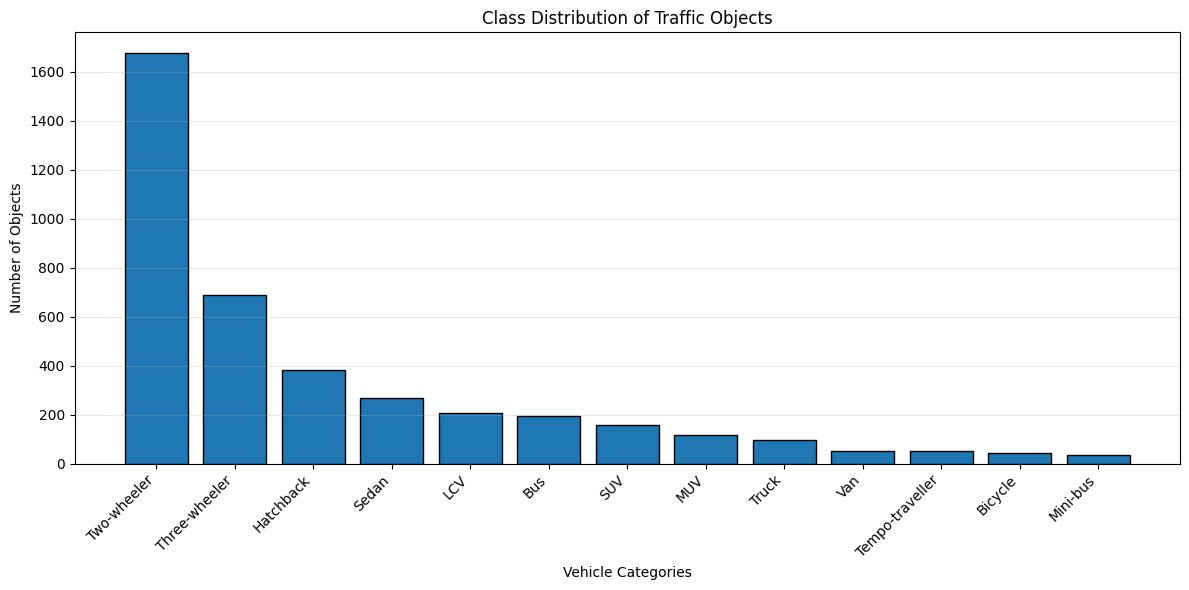

In [14]:

plt.figure(figsize=(12, 6))

plt.bar(
    class_df["Class"],
    class_df["Object Count"],
    edgecolor="black"
)

plt.title("Class Distribution of Traffic Objects")
plt.xlabel("Vehicle Categories")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

# Annotation validation

missing_images = []
invalid_boxes = []
invalid_categories = []

for img in selected_images:

    image_id = img["id"]
    image_path = os.path.join(
        "/content/bmd45_sample/BMD-45-Train",
        img["file_name"]
    )

    if not os.path.exists(image_path):
        missing_images.append(image_id)

for ann in coco_data["annotations"]:

    if ann["image_id"] not in selected_ids:
        continue

    x, y, w, h = ann["bbox"]

    img = image_lookup[ann["image_id"]]

    img_width = img["width"]
    img_height = img["height"]

    # Check invalid bounding boxes
    if (
        w <= 0 or h <= 0 or
        x < 0 or y < 0 or
        x + w > img_width or
        y + h > img_height
    ):
        invalid_boxes.append(ann["id"])

    # Check invalid category IDs
    if ann["category_id"] not in categories:
        invalid_categories.append(ann["id"])


print("ANNOTATION VALIDATION RESULTS")
print("--------------------------------")
print("Missing images:", len(missing_images))
print("Invalid bounding boxes:", len(invalid_boxes))
print("Invalid categories:", len(invalid_categories))


ANNOTATION VALIDATION RESULTS
--------------------------------
Missing images: 0
Invalid bounding boxes: 0
Invalid categories: 0


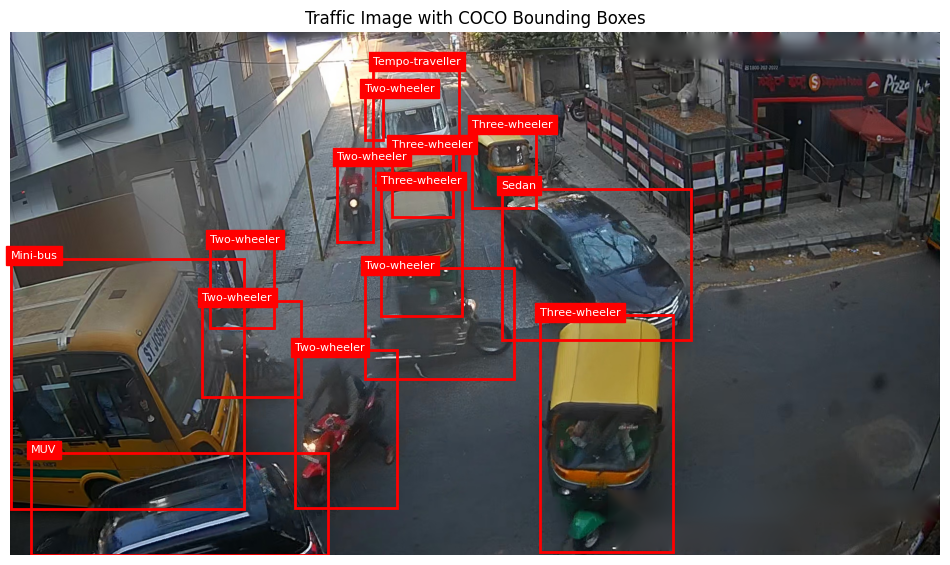

In [16]:

# Display one annotated image

img_info = selected_images[0]

image_path = os.path.join(
    "/content/bmd45_sample/BMD-45-Train",
    img_info["file_name"]
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image)

for ann in coco_data["annotations"]:

    if ann["image_id"] != img_info["id"]:
        continue

    x, y, w, h = ann["bbox"]

    rect = plt.Rectangle(
        (x, y), w, h,
        fill=False,
        edgecolor="red",
        linewidth=2
    )

    plt.gca().add_patch(rect)

    label = categories[ann["category_id"]]

    plt.text(
        x, y,
        label,
        color="white",
        backgroundcolor="red",
        fontsize=8
    )

plt.title("Traffic Image with COCO Bounding Boxes")
plt.axis("off")
plt.show()


In [17]:

print("FINAL ANNOTATION AUDIT")
print("=======================")

print("Total selected images:", len(selected_images))
print("Total downloaded images:", len(image_files))
print("Missing images:", len(missing_images))
print("Invalid bounding boxes:", len(invalid_boxes))
print("Invalid category IDs:", len(invalid_categories))

print("\nDataset validation completed!")


FINAL ANNOTATION AUDIT
Total selected images: 300
Total downloaded images: 300
Missing images: 0
Invalid bounding boxes: 0
Invalid category IDs: 0

Dataset validation completed!


In [18]:

# Export image quality results

quality_df.to_csv(
    "image_quality_report.csv",
    index=False
)

print("Image quality report exported successfully!")
print("Total records:", len(quality_df))


Image quality report exported successfully!
Total records: 300


In [19]:

# Export class distribution results

class_df.to_csv(
    "class_distribution_report.csv",
    index=False
)

print("Class distribution report exported successfully!")
display(class_df)


Class distribution report exported successfully!


,Class,Object Count
0,Two-wheeler,1678
4,Three-wheeler,689
1,Hatchback,384
8,Sedan,268
6,LCV,206
11,Bus,193
2,SUV,158
5,MUV,118
3,Truck,97
10,Van,52


In [20]:

# Generate final dataset audit report

from datetime import datetime

total_objects = int(class_df["Object Count"].sum())
total_classes = len(class_df)

most_common = class_df.iloc[0]
least_common = class_df.iloc[-1]

quality_counts = quality_df["Quality"].value_counts()

report = f"""
DATASET AUDIT AND VISUALISATION REPORT
======================================

Dataset: BMD-45 Indian Traffic Dataset
Analysis Sample: 300 Images

1. IMAGE QUALITY ANALYSIS
-------------------------
Images analysed: {len(quality_df)}
Average brightness: {quality_df['Brightness'].mean():.2f}
Average sharpness: {quality_df['Sharpness'].mean():.2f}

Quality Distribution:
{quality_counts.to_string()}

2. CLASS DISTRIBUTION
---------------------
Total categories: {total_classes}
Total annotated objects: {total_objects}

Most frequent class:
{most_common['Class']} - {most_common['Object Count']}

Least frequent class:
{least_common['Class']} - {least_common['Object Count']}

3. ANNOTATION VALIDATION
------------------------
Selected images: {len(selected_images)}
Downloaded images: {len(image_files)}
Missing images: {len(missing_images)}
Invalid bounding boxes: {len(invalid_boxes)}
Invalid category IDs: {len(invalid_categories)}

4. CONCLUSION
-------------
The dataset audit was successfully performed on a
sample of 300 Indian traffic images.

Image dimensions, brightness, sharpness, class
distribution and COCO annotations were analysed.

The selected sample contained different image-quality
levels and multiple vehicle categories.

No missing images, invalid bounding boxes or invalid
category IDs were detected.

Note: Results represent the selected 300-image sample,
not the entire BMD-45 dataset.

======================================
END OF REPORT
"""

with open("final_dataset_audit_report.txt", "w") as f:
    f.write(report)

print(report)
print("Final audit report generated!")



DATASET AUDIT AND VISUALISATION REPORT

Dataset: BMD-45 Indian Traffic Dataset
Analysis Sample: 300 Images

1. IMAGE QUALITY ANALYSIS
-------------------------
Images analysed: 300
Average brightness: 136.59
Average sharpness: 633.56

Quality Distribution:
Quality
Clear        155
Moderate     130
Blurry         9
Low Light      6

2. CLASS DISTRIBUTION
---------------------
Total categories: 13
Total annotated objects: 3971

Most frequent class:
Two-wheeler - 1678

Least frequent class:
Mini-bus - 33

3. ANNOTATION VALIDATION
------------------------
Selected images: 300
Downloaded images: 300
Missing images: 0
Invalid bounding boxes: 0
Invalid category IDs: 0

4. CONCLUSION
-------------
The dataset audit was successfully performed on a
sample of 300 Indian traffic images.

Image dimensions, brightness, sharpness, class
distribution and COCO annotations were analysed.

The selected sample contained different image-quality
levels and multiple vehicle categories.

No missing images, i